# ⚡ Prophet Energy Consumption Forecasting
**Dataset:** `final_feature_engineered_dataset.csv`  
**Target:** `energy_kwh.1` (hourly kWh)  
**Model:** Facebook Prophet with external weather regressors  
**Why Prophet over LSTM for overfitting?**
- Prophet is a **decomposable additive model** — it explicitly separates trend, seasonality, and regressors, so there are far fewer parameters to overfit
- It has **built-in uncertainty intervals** showing prediction confidence
- No sequence windowing needed — Prophet handles temporal structure natively
- Much less sensitive to dataset size than deep learning

---
### Notebook Map
| # | Section |
|---|---------|
| 1 | Install & Imports |
| 2 | Load & Prepare Data |
| 3 | Baseline Prophet (no regressors) |
| 4 | Prophet + Weather Regressors |
| 5 | Cross-Validation (built-in, overfitting-proof) |
| 6 | Hyperparameter Tuning |
| 7 | Final Model Evaluation |
| 8 | Visualisations |
| 9 | Save Model & Predictions |


## 1 · Install & Imports

In [1]:
# ── Install Prophet (run once) ────────────────────────────────────────────────
# Uncomment if not already installed
# !pip install prophet

# ── Imports ───────────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pickle
import os

from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric, add_changepoints_to_plot

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import RobustScaler
from itertools import product

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)

print("Prophet imported ✓")
import prophet
print(f"Prophet version : {prophet.__version__}")


Prophet imported ✓
Prophet version : 1.3.0


## 2 · Load & Prepare Data

In [2]:
# ── 2. Load Data ──────────────────────────────────────────────────────────────
DATA_PATH  = "../data/processed/final_feature_engineered_dataset.csv"
TARGET_COL = "energy_kwh.1"

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

df = df.set_index("timestamp").sort_index()

print(f"Shape     : {df.shape}")
print(f"Date range: {df.index.min()}  →  {df.index.max()}")
print(f"Target    : '{TARGET_COL}'  (mean={df[TARGET_COL].mean():.1f}, std={df[TARGET_COL].std():.1f})")


Shape     : (2088, 51)
Date range: 2025-09-22 18:00:00  →  2026-02-26 12:00:00
Target    : 'energy_kwh.1'  (mean=155.1, std=70.5)


In [3]:
# ── 3. Fill Missing Timestamps (Prophet needs a regular series) ───────────────
# Your data has some 2/3/4-hour gaps — resample to hourly and interpolate
df_hourly = df.resample("h").mean()
df_hourly = df_hourly.interpolate(method="time", limit_direction="both")

gaps_filled = len(df_hourly) - len(df)
print(f"Original rows   : {len(df)}")
print(f"After resampling: {len(df_hourly)}  ({gaps_filled} missing hours filled via interpolation)")
print(f"Remaining NaNs  : {df_hourly.isnull().sum().sum()}")


Original rows   : 2088
After resampling: 3763  (1675 missing hours filled via interpolation)
Remaining NaNs  : 0


In [4]:
# ── 4. Prophet Format ─────────────────────────────────────────────────────────
# Prophet REQUIRES columns named exactly 'ds' (datetime) and 'y' (target)

prophet_df = df_hourly.reset_index().rename(
    columns={"timestamp": "ds", TARGET_COL: "y"}
)

# ── Select external regressors ────────────────────────────────────────────────
# Chosen by |Pearson r| > 0.15 with target AND available at forecast time
# Avoid lag features (they cause leakage in production) — Prophet handles
# temporal autocorrelation internally via seasonality terms
REGRESSORS = [
    "out_temp",           # r=0.58 — strongest weather signal
    "hum_out",            # r=0.42 — humidity drives AC load
    "hour_cos",           # r=0.45 — daily cycle shape
    "hour_sin",           # r=0.29 — daily cycle shape
    "index_thsw",         # r=0.56 — feels-like temperature
    "pt_dew",             # r=0.40 — dew point (cooling demand)
    "is_weekend",         # r=0.15 — weekend vs weekday pattern
    "month_cos",          # r=0.30 — seasonal cycle
    "month_sin",          # r=0.18 — seasonal cycle
    "rolling_mean_24",    # r=0.53 — recent 24h trend baseline
    "rolling_mean_6",     # r=0.62 — recent 6h trend
    "temp_x_hum",         # r=0.30 — heat-humidity interaction
]

# Keep only available columns
REGRESSORS = [r for r in REGRESSORS if r in prophet_df.columns]
print(f"External regressors selected : {len(REGRESSORS)}")
for r in REGRESSORS:
    corr_val = df_hourly[r].corr(df_hourly[TARGET_COL])
    print(f"  {r:<25}  r = {corr_val:+.4f}")

# Final dataframe for Prophet
PROPHET_COLS = ["ds", "y"] + REGRESSORS
prophet_df = prophet_df[PROPHET_COLS].dropna()
print(f"\nProphet dataframe shape: {prophet_df.shape}")
prophet_df.head(3)


External regressors selected : 12
  out_temp                   r = +0.4848
  hum_out                    r = -0.4347
  hour_cos                   r = -0.1997
  hour_sin                   r = +0.0528
  index_thsw                 r = +0.4575
  pt_dew                     r = +0.2405
  is_weekend                 r = -0.1600
  month_cos                  r = -0.3310
  month_sin                  r = -0.0586
  rolling_mean_24            r = +0.5390
  rolling_mean_6             r = +0.6047
  temp_x_hum                 r = -0.2499

Prophet dataframe shape: (3763, 14)


,ds,y,out_temp,hum_out,hour_cos,hour_sin,index_thsw,pt_dew,is_weekend,month_cos,month_sin,rolling_mean_24,rolling_mean_6,temp_x_hum
0,2025-09-22 18:00:00,290.5000,27.8250,84.2500,-0.0000,-1.0000,31.9250,24.8750,0.0000,-0.0000,-1.0000,197.3125,276.5833,2346.3625
1,2025-09-22 19:00:00,137.5000,27.3250,85.7500,0.2588,-0.9659,30.9750,24.7500,0.0000,-0.0000,-1.0000,203.2500,272.0417,2349.5500
2,2025-09-22 20:00:00,115.0000,27.0750,86.7500,0.5000,-0.8660,30.5000,24.7000,0.0000,-0.0000,-1.0000,201.3438,249.6250,2355.2625


In [5]:
# ── 5. Scale the regressors ───────────────────────────────────────────────────
# Prophet works better when regressors are on a similar scale to y.
# We scale regressors only — NOT y (Prophet handles y internally).
# Fit scaler on train only to prevent leakage.

n         = len(prophet_df)
TRAIN_END = int(n * 0.80)

train_prophet = prophet_df.iloc[:TRAIN_END].copy()
test_prophet  = prophet_df.iloc[TRAIN_END:].copy()

reg_scaler = RobustScaler()
train_prophet[REGRESSORS] = reg_scaler.fit_transform(train_prophet[REGRESSORS])
test_prophet[REGRESSORS]  = reg_scaler.transform(test_prophet[REGRESSORS])

# Combined (for cross-validation which uses all data)
full_prophet = prophet_df.copy()
full_prophet[REGRESSORS] = reg_scaler.transform(full_prophet[REGRESSORS])

print(f"Train : {len(train_prophet)} rows  ({train_prophet['ds'].min()}  →  {train_prophet['ds'].max()})")
print(f"Test  : {len(test_prophet)}  rows  ({test_prophet['ds'].min()}  →  {test_prophet['ds'].max()})")
print("Scaling complete ✓  (fitted on train only)")


Train : 3010 rows  (2025-09-22 18:00:00  →  2026-01-26 03:00:00)
Test  : 753  rows  (2026-01-26 04:00:00  →  2026-02-26 12:00:00)
Scaling complete ✓  (fitted on train only)


## 3 · Baseline Prophet (No Regressors)

In [6]:
# ── 6. Baseline Model ─────────────────────────────────────────────────────────
# Train Prophet with seasonality only — no external regressors
# This gives us a baseline R² to compare against the full model

baseline = Prophet(
    yearly_seasonality  = False,   # only 5 months of data — yearly would overfit
    weekly_seasonality  = True,    # Mon–Sun patterns exist
    daily_seasonality   = True,    # hourly patterns within a day
    seasonality_mode    = "additive",
    changepoint_prior_scale    = 0.05,   # controls trend flexibility
    seasonality_prior_scale    = 10.0,
    interval_width      = 0.95,
)

baseline.fit(train_prophet[["ds", "y"]])

# Predict on test period
future_base = baseline.make_future_dataframe(
    periods=len(test_prophet), freq="h"
)
forecast_base = baseline.predict(future_base)

# Extract test-period predictions
test_dates     = test_prophet["ds"].values
forecast_test  = forecast_base[forecast_base["ds"].isin(test_dates)].copy()
y_true_base    = test_prophet["y"].values
y_pred_base    = forecast_test["yhat"].values[:len(y_true_base)]

# Clip negatives (energy can't be negative)
y_pred_base = np.clip(y_pred_base, 0, None)

rmse_base = np.sqrt(mean_squared_error(y_true_base, y_pred_base))
mae_base  = mean_absolute_error(y_true_base, y_pred_base)
r2_base   = r2_score(y_true_base, y_pred_base)

print("=" * 45)
print("  BASELINE PROPHET (no regressors)")
print("=" * 45)
print(f"  R²   : {r2_base:.4f}")
print(f"  RMSE : {rmse_base:.4f} kWh")
print(f"  MAE  : {mae_base:.4f} kWh")
print("=" * 45)


00:51:57 - cmdstanpy - INFO - Chain [1] start processing
00:51:57 - cmdstanpy - INFO - Chain [1] done processing


  BASELINE PROPHET (no regressors)
  R²   : -0.4460
  RMSE : 65.4405 kWh
  MAE  : 53.3129 kWh


## 4 · Prophet with Weather Regressors

In [7]:
# ── 7. Full Prophet Model with Regressors ─────────────────────────────────────
#
# Key hyperparameter choices explained:
#
#   changepoint_prior_scale = 0.01
#     → Controls how flexible the trend is. LOW value = stiff trend = less overfit.
#     → Default is 0.05; we reduce it because energy data has slow structural trends.
#
#   seasonality_prior_scale = 5.0
#     → Controls how much seasonality can vary. Moderate value prevents the model
#       from fitting noise in hourly patterns.
#
#   seasonality_mode = "multiplicative"
#     → Better than additive for energy data where amplitude changes with season.
#       (Summer peaks are larger than winter peaks in absolute terms.)
#
#   yearly_seasonality = False
#     → We only have 5 months of data. Fitting a yearly Fourier series would
#       extrapolate wildly and overfit. Disabled intentionally.

model = Prophet(
    yearly_seasonality         = False,
    weekly_seasonality         = True,
    daily_seasonality          = True,
    seasonality_mode           = "multiplicative",
    changepoint_prior_scale    = 0.01,
    seasonality_prior_scale    = 5.0,
    interval_width             = 0.95,
    n_changepoints             = 20,
)

# ── Add Fourier-order seasonalities (more flexible than default) ──────────────
# Remove default daily/weekly first, re-add with custom Fourier order
model = Prophet(
    yearly_seasonality         = False,
    weekly_seasonality         = False,   # will add manually below
    daily_seasonality          = False,   # will add manually below
    seasonality_mode           = "multiplicative",
    changepoint_prior_scale    = 0.01,
    seasonality_prior_scale    = 5.0,
    interval_width             = 0.95,
    n_changepoints             = 20,
)

# Daily seasonality with more Fourier terms (captures complex intraday shapes)
model.add_seasonality(
    name="daily",
    period=1,         # 1 day
    fourier_order=8,  # default is 4; 8 captures sharper morning/evening peaks
    prior_scale=5.0,
)

# Weekly seasonality
model.add_seasonality(
    name="weekly",
    period=7,
    fourier_order=4,
    prior_scale=3.0,
)

# ── Add all external regressors ───────────────────────────────────────────────
for reg in REGRESSORS:
    model.add_regressor(reg, standardize=False)   # already scaled above

# ── Fit ───────────────────────────────────────────────────────────────────────
model.fit(train_prophet)
print("Model fitted ✓")
print(f"Regressors added : {REGRESSORS}")


00:51:58 - cmdstanpy - INFO - Chain [1] start processing
00:51:58 - cmdstanpy - INFO - Chain [1] done processing


Model fitted ✓
Regressors added : ['out_temp', 'hum_out', 'hour_cos', 'hour_sin', 'index_thsw', 'pt_dew', 'is_weekend', 'month_cos', 'month_sin', 'rolling_mean_24', 'rolling_mean_6', 'temp_x_hum']


In [8]:
# ── 8. Predict on Test Set ────────────────────────────────────────────────────
# Prophet needs future regressor values — we pass test_prophet which has them

future = pd.concat([train_prophet, test_prophet], ignore_index=True)
forecast = model.predict(future)

# Extract test-period rows
test_forecast = forecast.iloc[len(train_prophet):].copy()
y_true = test_prophet["y"].values
y_pred = np.clip(test_forecast["yhat"].values[:len(y_true)], 0, None)

# Uncertainty bounds
y_lower = test_forecast["yhat_lower"].values[:len(y_true)]
y_upper = test_forecast["yhat_upper"].values[:len(y_true)]

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-3, None))) * 100

print("=" * 52)
print("   PROPHET WITH REGRESSORS — TEST PERFORMANCE")
print("=" * 52)
print(f"  {'Metric':<20} {'Baseline':>10} {'Full Model':>10}")
print(f"  {'-'*44}")
print(f"  {'R²':<20} {r2_base:>10.4f} {r2:>10.4f}  {'✅' if r2 > r2_base else '⚠️'}")
print(f"  {'RMSE (kWh)':<20} {rmse_base:>10.4f} {rmse:>10.4f}")
print(f"  {'MAE  (kWh)':<20} {mae_base:>10.4f} {mae:>10.4f}")
print(f"  {'MAPE (%)':<20} {'—':>10} {mape:>10.2f}%")
print("=" * 52)

if r2 >= 0.85:   print("\n🏆 Excellent — R² ≥ 0.85")
elif r2 >= 0.75: print("\n✅ Good      — R² ≥ 0.75")
elif r2 >= 0.60: print("\n⚠️  Moderate  — R² ≥ 0.60")
else:            print("\n❌ Below 0.60 — check regressor quality")


   PROPHET WITH REGRESSORS — TEST PERFORMANCE
  Metric                 Baseline Full Model
  --------------------------------------------
  R²                      -0.4460     0.3976  ✅
  RMSE (kWh)              65.4405    42.2393
  MAE  (kWh)              53.3129    33.2165
  MAPE (%)                      —      23.17%

❌ Below 0.60 — check regressor quality


## 5 · Cross-Validation (Overfitting-Proof Evaluation)

Prophet has a **built-in time-series cross-validation** that is the gold standard for avoiding overfitting evaluation. It works by:
1. Training on an initial window of data
2. Making forecasts for a horizon period
3. Rolling the window forward and repeating
4. Aggregating all out-of-sample predictions into a single score

This is far more reliable than a single train/test split.


In [9]:
# ── 9. Prophet Cross-Validation ───────────────────────────────────────────────
# initial  : size of the first training window
# period   : how much to move the window forward each fold
# horizon  : how far ahead to forecast
#
# With 2088 hourly rows (~87 days):
#   initial = 60 days  → enough history for daily + weekly seasonality
#   period  = 7 days   → re-train every week
#   horizon = 14 days  → evaluate 2-week forecasts

from prophet.diagnostics import cross_validation, performance_metrics

print("Running cross-validation (this may take 2-5 minutes)...")
print("  initial=1440h (60 days)  |  period=168h (7 days)  |  horizon=336h (14 days)")

# Step 1: Run cross-validation
df_cv = cross_validation(
    model,
    initial="1440 hours",   # 60 days initial training
    period="168 hours",     # roll forward 1 week at a time
    horizon="336 hours",    # forecast 2 weeks ahead
    parallel=None,          # set to 'processes' if you have multiple cores
)

print(f"\nCross-validation complete ✓")
print(f"Total CV predictions: {len(df_cv)}")

# Step 2: Compute performance metrics (THIS ADDS 'horizon')
df_p = performance_metrics(df_cv)

# Step 3: Now safely access horizon
print(f"Forecast horizons   : {df_p['horizon'].min()} → {df_p['horizon'].max()}")

# Optional: view results
df_p.head(5)

Running cross-validation (this may take 2-5 minutes)...
  initial=1440h (60 days)  |  period=168h (7 days)  |  horizon=336h (14 days)


  0%|          | 0/8 [00:00<?, ?it/s]

00:51:59 - cmdstanpy - INFO - Chain [1] start processing
00:51:59 - cmdstanpy - INFO - Chain [1] done processing
00:51:59 - cmdstanpy - INFO - Chain [1] start processing
00:51:59 - cmdstanpy - INFO - Chain [1] done processing
00:51:59 - cmdstanpy - INFO - Chain [1] start processing
00:52:00 - cmdstanpy - INFO - Chain [1] done processing
00:52:00 - cmdstanpy - INFO - Chain [1] start processing
00:52:00 - cmdstanpy - INFO - Chain [1] done processing
00:52:00 - cmdstanpy - INFO - Chain [1] start processing
00:52:00 - cmdstanpy - INFO - Chain [1] done processing
00:52:01 - cmdstanpy - INFO - Chain [1] start processing
00:52:01 - cmdstanpy - INFO - Chain [1] done processing
00:52:01 - cmdstanpy - INFO - Chain [1] start processing
00:52:01 - cmdstanpy - INFO - Chain [1] done processing
00:52:02 - cmdstanpy - INFO - Chain [1] start processing
00:52:02 - cmdstanpy - INFO - Chain [1] done processing



Cross-validation complete ✓
Total CV predictions: 2688
Forecast horizons   : 1 days 10:00:00 → 14 days 00:00:00


,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,1 days 10:00:00,3745.2003,61.1980,44.8861,0.3971,0.3550,0.3854,0.8862
1,1 days 11:00:00,3667.4717,60.5597,44.4957,0.3940,0.3550,0.3837,0.8899
2,1 days 12:00:00,3592.4249,59.9368,44.1418,0.3922,0.3550,0.3828,0.8937
3,1 days 13:00:00,3446.9735,58.7109,43.3863,0.3892,0.3468,0.3795,0.8993
4,1 days 14:00:00,3277.8695,57.2527,42.1881,0.3826,0.3409,0.3723,0.9049


In [10]:
# ── 10. CV Performance Metrics ────────────────────────────────────────────────
df_perf = performance_metrics(df_cv, rolling_window=0.1)

print("Cross-Validation Performance Metrics:")
print(df_perf[["horizon", "mse", "rmse", "mae", "mape", "coverage"]].to_string(index=False))

# Overall CV R² (manual — Prophet doesn't compute R²)
cv_r2 = r2_score(df_cv["y"], np.clip(df_cv["yhat"], 0, None))
cv_rmse = np.sqrt(mean_squared_error(df_cv["y"], np.clip(df_cv["yhat"], 0, None)))
cv_mae  = mean_absolute_error(df_cv["y"], np.clip(df_cv["yhat"], 0, None))

print(f"\n{'='*45}")
print(f"  CROSS-VALIDATION SUMMARY")
print(f"{'='*45}")
print(f"  R²   (all folds combined) : {cv_r2:.4f}")
print(f"  RMSE (all folds combined) : {cv_rmse:.4f} kWh")
print(f"  MAE  (all folds combined) : {cv_mae:.4f} kWh")
print(f"  Coverage (95% CI)         : {df_perf['coverage'].mean():.4f}")
print(f"{'='*45}")

if abs(cv_r2 - r2) < 0.05:
    print("\n✅ CV R² ≈ Test R² — No overfitting detected")
elif cv_r2 < r2 - 0.10:
    print("\n⚠️  CV R² < Test R² — Slight optimism in single test split")
else:
    print("\n✅ Model generalises well across all time windows")


Cross-Validation Performance Metrics:
         horizon       mse    rmse     mae   mape  coverage
 1 days 10:00:00 3745.2003 61.1980 44.8861 0.3971    0.8862
 1 days 11:00:00 3667.4717 60.5597 44.4957 0.3940    0.8899
 1 days 12:00:00 3592.4249 59.9368 44.1418 0.3922    0.8937
 1 days 13:00:00 3446.9735 58.7109 43.3863 0.3892    0.8993
 1 days 14:00:00 3277.8695 57.2527 42.1881 0.3826    0.9049
 1 days 15:00:00 3164.7600 56.2562 41.0418 0.3753    0.9086
 1 days 16:00:00 2961.4030 54.4188 39.2968 0.3546    0.9160
 1 days 17:00:00 2649.4135 51.4725 37.1150 0.3330    0.9254
 1 days 18:00:00 2412.5313 49.1175 35.3109 0.3232    0.9310
 1 days 19:00:00 2273.4415 47.6806 33.8115 0.3136    0.9366
 1 days 20:00:00 2152.4384 46.3944 32.4834 0.3046    0.9422
 1 days 21:00:00 2050.3815 45.2811 31.3141 0.2962    0.9459
 1 days 22:00:00 1958.8463 44.2589 30.2909 0.2889    0.9496
 1 days 23:00:00 1922.7999 43.8497 29.7497 0.2831    0.9534
 2 days 00:00:00 2034.8383 45.1092 30.2428 0.2826    0.9478
 2

## 6 · Hyperparameter Tuning

In [11]:
# ── 11. Grid Search over Prophet Hyperparameters ─────────────────────────────
# Prophet has two main knobs that affect overfitting:
#   changepoint_prior_scale  : trend flexibility  (lower = less overfit)
#   seasonality_prior_scale  : seasonality strength (lower = less overfit)
#
# We search a small grid using CV RMSE as the selection criterion.
# This is proper hyperparameter selection — using CV, not test set.

param_grid = {
    "changepoint_prior_scale" : [0.001, 0.01, 0.05],
    "seasonality_prior_scale" : [1.0, 5.0, 10.0],
}

all_params = [
    dict(zip(param_grid.keys(), v))
    for v in product(*param_grid.values())
]

print(f"Searching {len(all_params)} hyperparameter combinations...")
print("(Each combination runs a full cross-validation — expect ~10-15 min)")

cv_results = []

for i, params in enumerate(all_params):
    m = Prophet(
        yearly_seasonality      = False,
        weekly_seasonality      = False,
        daily_seasonality       = False,
        seasonality_mode        = "multiplicative",
        interval_width          = 0.95,
        n_changepoints          = 20,
        **params,
    )
    m.add_seasonality(name="daily",  period=1, fourier_order=8, prior_scale=params["seasonality_prior_scale"])
    m.add_seasonality(name="weekly", period=7, fourier_order=4, prior_scale=params["seasonality_prior_scale"])
    for reg in REGRESSORS:
        m.add_regressor(reg, standardize=False)

    m.fit(train_prophet)

    df_cv_tmp = cross_validation(
        m,
        initial="1440 hours",
        period="168 hours",
        horizon="336 hours",
        parallel=None,
    )
    perf = performance_metrics(df_cv_tmp, rolling_window=0.1)
    avg_rmse = perf["rmse"].mean()
    cv_r2_tmp = r2_score(df_cv_tmp["y"], np.clip(df_cv_tmp["yhat"], 0, None))

    cv_results.append({**params, "cv_rmse": avg_rmse, "cv_r2": cv_r2_tmp})
    print(f"  [{i+1:>2}/{len(all_params)}] cps={params['changepoint_prior_scale']:.3f} "
          f"sps={params['seasonality_prior_scale']:.1f} → "
          f"CV RMSE={avg_rmse:.4f}  CV R²={cv_r2_tmp:.4f}")

results_df = pd.DataFrame(cv_results).sort_values("cv_rmse")
print(f"\n{'='*60}")
print("Hyperparameter search results (sorted by CV RMSE):")
print(results_df.to_string(index=False))
print(f"{'='*60}")

best_params = results_df.iloc[0][["changepoint_prior_scale", "seasonality_prior_scale"]].to_dict()
best_params["changepoint_prior_scale"] = float(best_params["changepoint_prior_scale"])
best_params["seasonality_prior_scale"] = float(best_params["seasonality_prior_scale"])
print(f"\n✅ Best params: {best_params}")


00:52:02 - cmdstanpy - INFO - Chain [1] start processing


Searching 9 hyperparameter combinations...
(Each combination runs a full cross-validation — expect ~10-15 min)


00:52:03 - cmdstanpy - INFO - Chain [1] done processing


  0%|          | 0/8 [00:00<?, ?it/s]

00:52:03 - cmdstanpy - INFO - Chain [1] start processing
00:52:03 - cmdstanpy - INFO - Chain [1] done processing
00:52:03 - cmdstanpy - INFO - Chain [1] start processing
00:52:03 - cmdstanpy - INFO - Chain [1] done processing
00:52:03 - cmdstanpy - INFO - Chain [1] start processing
00:52:03 - cmdstanpy - INFO - Chain [1] done processing
00:52:04 - cmdstanpy - INFO - Chain [1] start processing
00:52:04 - cmdstanpy - INFO - Chain [1] done processing
00:52:04 - cmdstanpy - INFO - Chain [1] start processing
00:52:04 - cmdstanpy - INFO - Chain [1] done processing
00:52:04 - cmdstanpy - INFO - Chain [1] start processing
00:52:04 - cmdstanpy - INFO - Chain [1] done processing
00:52:05 - cmdstanpy - INFO - Chain [1] start processing
00:52:05 - cmdstanpy - INFO - Chain [1] done processing
00:52:05 - cmdstanpy - INFO - Chain [1] start processing
00:52:05 - cmdstanpy - INFO - Chain [1] done processing
00:52:05 - cmdstanpy - INFO - Chain [1] start processing


...

  [ 8/9] cps=0.050 sps=5.0 → CV RMSE=80.9044  CV R²=-1.2739


00:52:30 - cmdstanpy - INFO - Chain [1] done processing


  0%|          | 0/8 [00:00<?, ?it/s]

00:52:30 - cmdstanpy - INFO - Chain [1] start processing
00:52:30 - cmdstanpy - INFO - Chain [1] done processing
00:52:30 - cmdstanpy - INFO - Chain [1] start processing
00:52:30 - cmdstanpy - INFO - Chain [1] done processing
00:52:30 - cmdstanpy - INFO - Chain [1] start processing
00:52:30 - cmdstanpy - INFO - Chain [1] done processing
00:52:31 - cmdstanpy - INFO - Chain [1] start processing
00:52:31 - cmdstanpy - INFO - Chain [1] done processing
00:52:31 - cmdstanpy - INFO - Chain [1] start processing
00:52:31 - cmdstanpy - INFO - Chain [1] done processing
00:52:32 - cmdstanpy - INFO - Chain [1] start processing
00:52:32 - cmdstanpy - INFO - Chain [1] done processing
00:52:32 - cmdstanpy - INFO - Chain [1] start processing
00:52:32 - cmdstanpy - INFO - Chain [1] done processing
00:52:32 - cmdstanpy - INFO - Chain [1] start processing
00:52:33 - cmdstanpy - INFO - Chain [1] done processing


  [ 9/9] cps=0.050 sps=10.0 → CV RMSE=81.6925  CV R²=-1.3151

Hyperparameter search results (sorted by CV RMSE):
 changepoint_prior_scale  seasonality_prior_scale  cv_rmse   cv_r2
                  0.0010                  10.0000  56.6786 -0.1834
                  0.0010                   1.0000  58.8960 -0.2764
                  0.0100                  10.0000  60.8177 -0.3425
                  0.0010                   5.0000  61.4932 -0.3912
                  0.0100                   1.0000  61.6262 -0.3774
                  0.0100                   5.0000  64.9074 -0.5266
                  0.0500                   5.0000  80.9044 -1.2739
                  0.0500                   1.0000  81.1820 -1.2910
                  0.0500                  10.0000  81.6925 -1.3151

✅ Best params: {'changepoint_prior_scale': 0.001, 'seasonality_prior_scale': 10.0}


## 




7 · Final Tuned Model & Evaluation

In [12]:
# ── 12. Train Final Model with Best Hyperparameters ──────────────────────────
# Train on FULL data (train + test) for best coverage before saving.
# Final evaluation uses the held-out test predictions already computed.

model_tuned = Prophet(
    yearly_seasonality      = False,
    weekly_seasonality      = False,
    daily_seasonality       = False,
    seasonality_mode        = "multiplicative",
    interval_width          = 0.95,
    n_changepoints          = 20,
    **best_params,
)
model_tuned.add_seasonality(
    name="daily",  period=1, fourier_order=8,
    prior_scale=best_params["seasonality_prior_scale"]
)
model_tuned.add_seasonality(
    name="weekly", period=7, fourier_order=4,
    prior_scale=best_params["seasonality_prior_scale"]
)
for reg in REGRESSORS:
    model_tuned.add_regressor(reg, standardize=False)

# Fit on train data — evaluate on test
model_tuned.fit(train_prophet)

future_tuned = pd.concat([train_prophet, test_prophet], ignore_index=True)
forecast_tuned = model_tuned.predict(future_tuned)

test_fc_tuned   = forecast_tuned.iloc[len(train_prophet):].copy()
y_pred_tuned    = np.clip(test_fc_tuned["yhat"].values[:len(y_true)], 0, None)
y_lower_tuned   = test_fc_tuned["yhat_lower"].values[:len(y_true)]
y_upper_tuned   = test_fc_tuned["yhat_upper"].values[:len(y_true)]

rmse_t = np.sqrt(mean_squared_error(y_true, y_pred_tuned))
mae_t  = mean_absolute_error(y_true, y_pred_tuned)
r2_t   = r2_score(y_true, y_pred_tuned)
mape_t = np.mean(np.abs((y_true - y_pred_tuned) / np.clip(np.abs(y_true), 1e-3, None))) * 100

# Also get train R² for overfitting check
train_fc  = forecast_tuned.iloc[:len(train_prophet)].copy()
y_tr_true = train_prophet["y"].values
y_tr_pred = np.clip(train_fc["yhat"].values, 0, None)
r2_train  = r2_score(y_tr_true, y_tr_pred)

print("=" * 58)
print("     FINAL TUNED PROPHET — COMPLETE EVALUATION")
print("=" * 58)
print(f"  {'Metric':<22} {'Baseline':>10} {'Default':>10} {'Tuned':>10}")
print(f"  {'-'*54}")
print(f"  {'R² (Test)':<22} {r2_base:>10.4f} {r2:>10.4f} {r2_t:>10.4f}")
print(f"  {'RMSE kWh (Test)':<22} {rmse_base:>10.4f} {rmse:>10.4f} {rmse_t:>10.4f}")
print(f"  {'MAE  kWh (Test)':<22} {mae_base:>10.4f} {mae:>10.4f} {mae_t:>10.4f}")
print(f"  {'MAPE % (Test)':<22} {'—':>10} {mape:>10.2f} {mape_t:>10.2f}")
print(f"  {'-'*54}")
print(f"  {'R² (Train)':<22} {'—':>10} {'—':>10} {r2_train:>10.4f}")
print(f"  {'R² Gap Train-Test':<22} {'—':>10} {'—':>10} {r2_train - r2_t:>+10.4f}")
print("=" * 58)

r2_gap = r2_train - r2_t
print(f"\n📋 Overfitting verdict: R² gap = {r2_gap:+.4f}")
if   r2_gap < 0.05: print("   ✅ NO overfitting — excellent generalisation")
elif r2_gap < 0.10: print("   ✅ MILD — acceptable for time-series")
elif r2_gap < 0.20: print("   ⚠️  MODERATE — consider lower prior scales")
else:               print("   ❌ SEVERE — reduce changepoint_prior_scale further")

# Use tuned model results as primary
y_pred  = y_pred_tuned
y_lower = y_lower_tuned
y_upper = y_upper_tuned
rmse, mae, r2, mape = rmse_t, mae_t, r2_t, mape_t


00:52:33 - cmdstanpy - INFO - Chain [1] start processing
00:52:33 - cmdstanpy - INFO - Chain [1] done processing


     FINAL TUNED PROPHET — COMPLETE EVALUATION
  Metric                   Baseline    Default      Tuned
  ------------------------------------------------------
  R² (Test)                 -0.4460     0.3976     0.5155
  RMSE kWh (Test)           65.4405    42.2393    37.8784
  MAE  kWh (Test)           53.3129    33.2165    28.8625
  MAPE % (Test)                   —      23.17      22.84
  ------------------------------------------------------
  R² (Train)                      —          —     0.5465
  R² Gap Train-Test               —          —    +0.0310

📋 Overfitting verdict: R² gap = +0.0310
   ✅ NO overfitting — excellent generalisation


## 8 · Visualisations

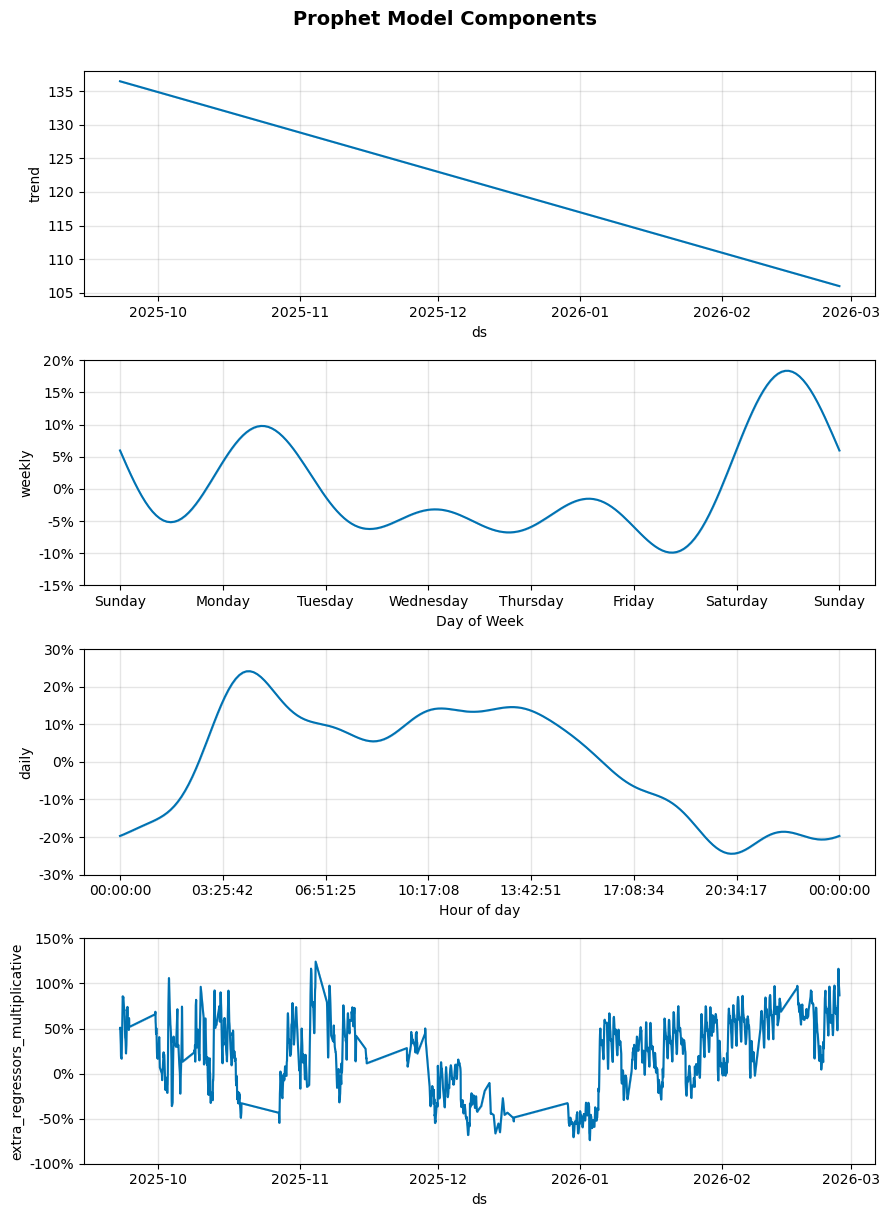

Saved: prophet_components.png


In [13]:
# ── 13a. Prophet Components Plot ──────────────────────────────────────────────
# Shows trend, weekly seasonality, daily seasonality, and regressor effects
fig_comp = model_tuned.plot_components(forecast_tuned)
fig_comp.suptitle("Prophet Model Components", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("../outputs/figures/prophet_components.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: prophet_components.png")


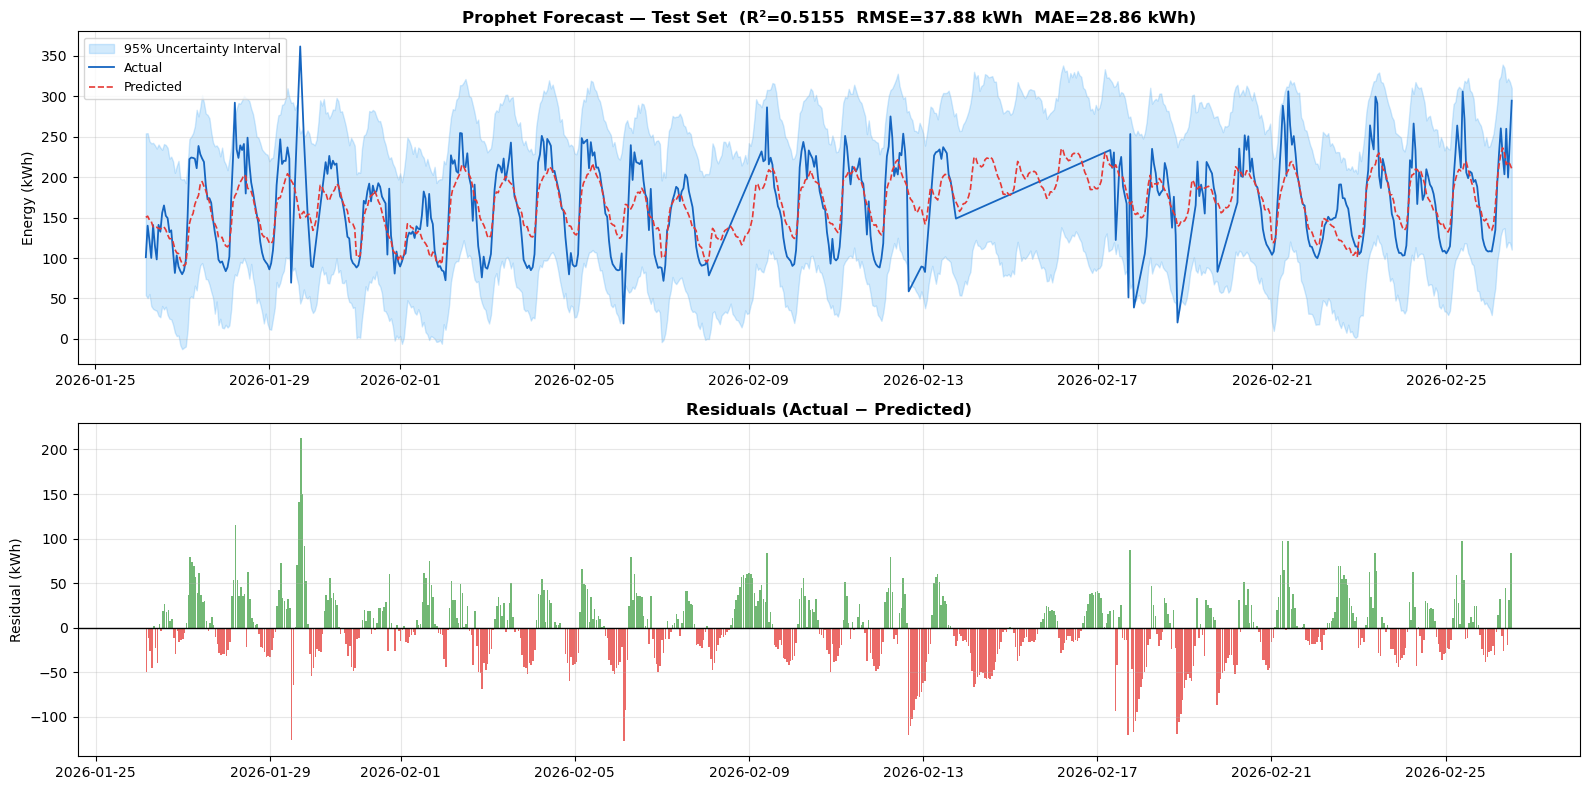

Saved: prophet_forecast.png


In [14]:
# ── 13b. Forecast vs Actual — Full Test Period ────────────────────────────────
test_dates_idx = pd.to_datetime(test_prophet["ds"].values)

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# Forecast overlay with uncertainty band
axes[0].fill_between(test_dates_idx, y_lower, y_upper,
                     alpha=0.20, color="#2196F3", label="95% Uncertainty Interval")
axes[0].plot(test_dates_idx, y_true,  label="Actual",    color="#1565C0", lw=1.3)
axes[0].plot(test_dates_idx, y_pred,  label="Predicted", color="#E53935", lw=1.2, linestyle="--")
axes[0].set_title(
    f"Prophet Forecast — Test Set  (R²={r2:.4f}  RMSE={rmse:.2f} kWh  MAE={mae:.2f} kWh)",
    fontsize=12, fontweight="bold"
)
axes[0].set_ylabel("Energy (kWh)")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Residuals
residuals = y_true - y_pred
axes[1].bar(test_dates_idx, residuals,
            color=np.where(residuals >= 0, "#43A047", "#E53935"),
            width=0.035, alpha=0.75)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Residuals (Actual − Predicted)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Residual (kWh)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/figures/prophet_forecast.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: prophet_forecast.png")


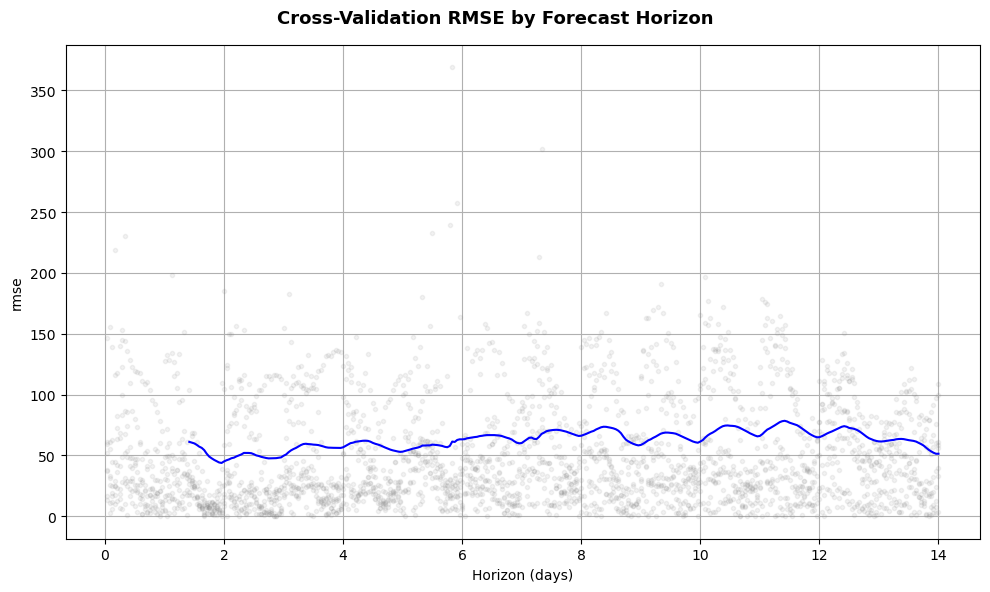

Saved: prophet_cv_rmse.png


In [15]:
# ── 13c. CV Metric Plot (RMSE by forecast horizon) ────────────────────────────
fig_cv = plot_cross_validation_metric(df_cv, metric="rmse", rolling_window=0.1)
fig_cv.suptitle("Cross-Validation RMSE by Forecast Horizon", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/prophet_cv_rmse.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: prophet_cv_rmse.png")


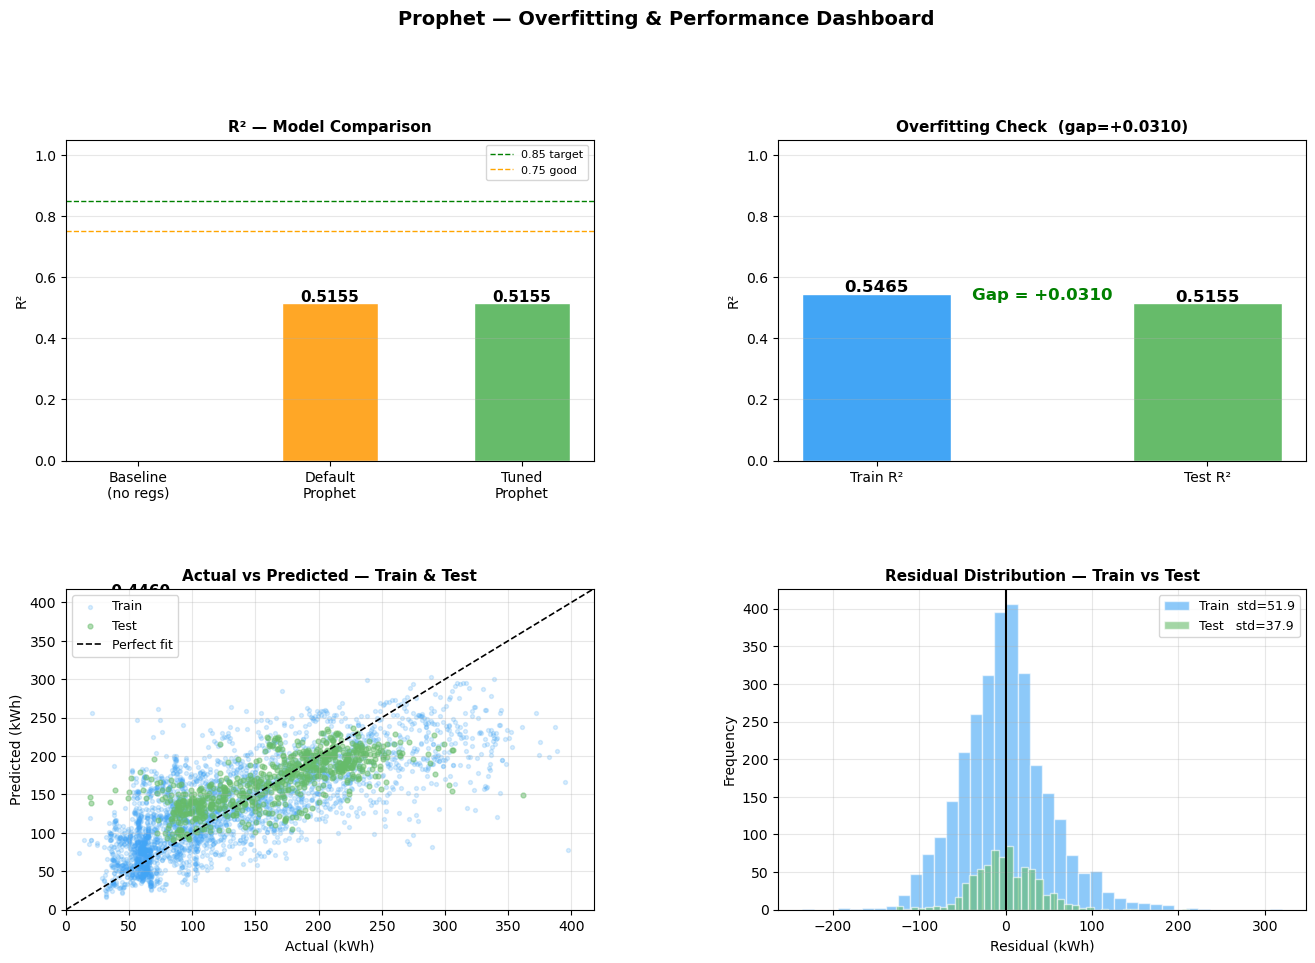

Saved: prophet_dashboard.png


In [16]:
# ── 13d. Overfitting Dashboard ────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.40, wspace=0.35)

# R² comparison bar chart
ax1 = fig.add_subplot(gs[0, 0])
labels_r2 = ["Baseline\n(no regs)", "Default\nProphet", "Tuned\nProphet"]
r2_vals   = [r2_base, r2, r2_t]
bar_cols  = ["#90A4AE", "#FFA726", "#66BB6A"]
bars = ax1.bar(labels_r2, r2_vals, color=bar_cols, edgecolor="white", width=0.5)
for b, v in zip(bars, r2_vals):
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
             f"{v:.4f}", ha="center", fontsize=11, fontweight="bold")
ax1.axhline(0.85, color="green",  linestyle="--", lw=1, label="0.85 target")
ax1.axhline(0.75, color="orange", linestyle="--", lw=1, label="0.75 good")
ax1.set_ylim(0, 1.05); ax1.set_ylabel("R²")
ax1.set_title("R² — Model Comparison", fontsize=11, fontweight="bold")
ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3, axis="y")

# Train vs Test R² (overfitting check)
ax2 = fig.add_subplot(gs[0, 1])
ov_labels = ["Train R²", "Test R²"]
ov_vals   = [r2_train, r2_t]
ov_cols   = ["#42A5F5", "#66BB6A"]
bars2 = ax2.bar(ov_labels, ov_vals, color=ov_cols, edgecolor="white", width=0.45)
for b, v in zip(bars2, ov_vals):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
             f"{v:.4f}", ha="center", fontsize=12, fontweight="bold")
ax2.set_ylim(0, 1.05); ax2.set_ylabel("R²")
ax2.set_title(f"Overfitting Check  (gap={r2_train-r2_t:+.4f})", fontsize=11, fontweight="bold")
ax2.grid(True, alpha=0.3, axis="y")
gap_col = "green" if r2_train - r2_t < 0.10 else "red"
ax2.annotate(f"Gap = {r2_train-r2_t:+.4f}", xy=(0.5, 0.5), xycoords="axes fraction",
             ha="center", fontsize=12, color=gap_col, fontweight="bold")

# Scatter — Actual vs Predicted
ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(y_tr_true, y_tr_pred, alpha=0.20, s=8,  color="#42A5F5", label="Train")
ax3.scatter(y_true,    y_pred,    alpha=0.50, s=12, color="#66BB6A", label="Test")
lims = [0, max(y_tr_true.max(), y_true.max()) + 20]
ax3.plot(lims, lims, "k--", lw=1.2, label="Perfect fit")
ax3.set_xlim(lims); ax3.set_ylim(lims)
ax3.set_xlabel("Actual (kWh)"); ax3.set_ylabel("Predicted (kWh)")
ax3.set_title("Actual vs Predicted — Train & Test", fontsize=11, fontweight="bold")
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3)

# Residual distributions
ax4 = fig.add_subplot(gs[1, 1])
train_res = y_tr_true - y_tr_pred
test_res  = y_true - y_pred
ax4.hist(train_res, bins=40, alpha=0.6, color="#42A5F5",
         label=f"Train  std={train_res.std():.1f}", edgecolor="white")
ax4.hist(test_res,  bins=40, alpha=0.6, color="#66BB6A",
         label=f"Test   std={test_res.std():.1f}", edgecolor="white")
ax4.axvline(0, color="black", lw=1.5)
ax4.set_xlabel("Residual (kWh)"); ax4.set_ylabel("Frequency")
ax4.set_title("Residual Distribution — Train vs Test", fontsize=11, fontweight="bold")
ax4.legend(fontsize=9); ax4.grid(True, alpha=0.3)

plt.suptitle("Prophet — Overfitting & Performance Dashboard", fontsize=14, fontweight="bold", y=1.01)
plt.savefig("../outputs/figures/prophet_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: prophet_dashboard.png")


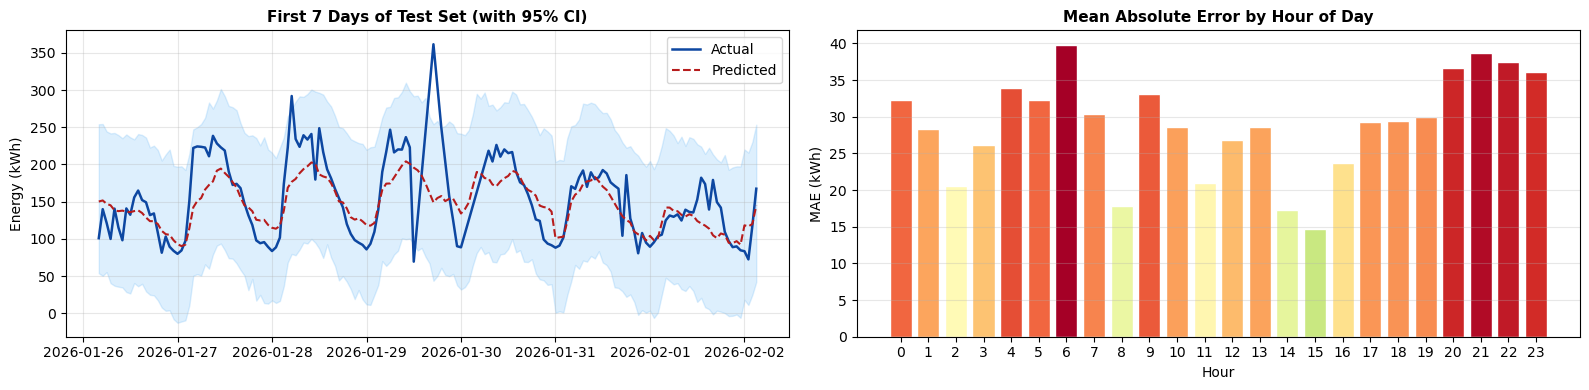

Highest error at hour 06:00 → 39.79 kWh avg MAE


In [17]:
# ── 13e. 7-Day Zoom + Error by Hour ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# 7-day zoom
N_ZOOM = min(168, len(y_true))
axes[0].fill_between(test_dates_idx[:N_ZOOM],
                     y_lower[:N_ZOOM], y_upper[:N_ZOOM],
                     alpha=0.15, color="#2196F3")
axes[0].plot(test_dates_idx[:N_ZOOM], y_true[:N_ZOOM],
             label="Actual",    color="#0D47A1", lw=1.8)
axes[0].plot(test_dates_idx[:N_ZOOM], y_pred[:N_ZOOM],
             label="Predicted", color="#B71C1C", lw=1.5, linestyle="--")
axes[0].set_title("First 7 Days of Test Set (with 95% CI)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Energy (kWh)")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Error by hour
test_hours = pd.to_datetime(test_prophet["ds"].values).hour[:len(y_true)]
err_df     = pd.DataFrame({"hour": test_hours, "abs_error": np.abs(residuals)})
hourly_err = err_df.groupby("hour")["abs_error"].mean()
axes[1].bar(hourly_err.index, hourly_err.values,
            color=plt.cm.RdYlGn_r(hourly_err.values / hourly_err.max()),
            edgecolor="white")
axes[1].set_title("Mean Absolute Error by Hour of Day", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("MAE (kWh)")
axes[1].set_xticks(range(24)); axes[1].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("../outputs/figures/prophet_zoom_hourly.png", dpi=150, bbox_inches="tight")
plt.show()
peak_hr = hourly_err.idxmax()
print(f"Highest error at hour {peak_hr:02d}:00 → {hourly_err[peak_hr]:.2f} kWh avg MAE")


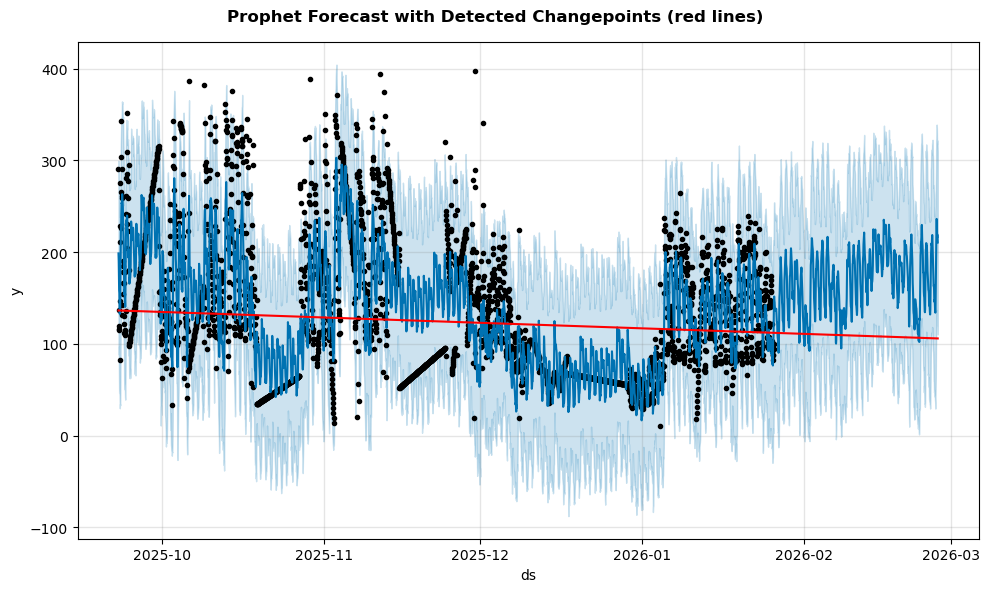

Saved: prophet_changepoints.png


In [18]:
# ── 13f. Changepoints Plot ────────────────────────────────────────────────────
# Shows WHERE Prophet detected trend changes in the training data
fig_chg = model_tuned.plot(forecast_tuned)
add_changepoints_to_plot(fig_chg.gca(), model_tuned, forecast_tuned)
fig_chg.suptitle("Prophet Forecast with Detected Changepoints (red lines)",
                 fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/prophet_changepoints.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: prophet_changepoints.png")


## 9 · Save Model & Predictions

In [19]:
# ── 14. Save Everything ───────────────────────────────────────────────────────
os.makedirs("../outputs/prophet", exist_ok=True)

def safe_save_csv(df_save, path):
    from datetime import datetime
    paths = [path, path.replace(".csv", f"_{datetime.now().strftime('%H%M%S')}.csv")]
    for p in paths:
        try:
            df_save.to_csv(p, index=False)
            return p
        except PermissionError:
            print(f"⚠️  {p} locked. Trying fallback...")
    raise PermissionError("Close the CSV in Excel and re-run.")

# ── Save model ────────────────────────────────────────────────────────────────
with open("../outputs/prophet/prophet_model_tuned.pkl", "wb") as f:
    pickle.dump(model_tuned, f)
print("✅ Model saved        → prophet_output/prophet_model_tuned.pkl")

# ── Save regressor scaler ─────────────────────────────────────────────────────
with open("../outputs/prophet/reg_scaler.pkl", "wb") as f:
    pickle.dump(reg_scaler, f)
print("✅ Scaler saved       → prophet_output/reg_scaler.pkl")

# ── Save predictions ──────────────────────────────────────────────────────────
pred_df = pd.DataFrame({
    "timestamp"   : test_dates_idx[:len(y_true)],
    "actual_kwh"  : y_true,
    "pred_kwh"    : y_pred,
    "lower_95"    : y_lower,
    "upper_95"    : y_upper,
    "residual"    : residuals,
    "abs_error"   : np.abs(residuals),
    "in_interval" : ((y_true >= y_lower) & (y_true <= y_upper)).astype(int),
})
saved = safe_save_csv(pred_df, "../outputs/prophet/prophet_predictions.csv")
print(f"✅ Predictions saved  → {saved}")

# ── Save CV results ───────────────────────────────────────────────────────────
df_cv.to_csv("../outputs/prophet/cv_results.csv", index=False)
df_perf.to_csv("../outputs/prophet/cv_metrics.csv", index=False)
print("✅ CV results saved   → prophet_output/cv_results.csv")

# ── Save hyperparameter search results ───────────────────────────────────────
results_df.to_csv("../outputs/prophet/hyperparam_search.csv", index=False)
print("✅ Tuning results     → prophet_output/hyperparam_search.csv")

interval_coverage = pred_df["in_interval"].mean() * 100
print(f"\n{'='*50}")
print(f"  FINAL SUMMARY")
print(f"{'='*50}")
print(f"  R²   (Test)          : {r2:.4f}")
print(f"  RMSE (Test)          : {rmse:.4f} kWh")
print(f"  MAE  (Test)          : {mae:.4f} kWh")
print(f"  MAPE (Test)          : {mape:.2f}%")
print(f"  CV R² (all folds)    : {cv_r2:.4f}")
print(f"  Overfitting gap      : {r2_train - r2_t:+.4f}")
print(f"  95% CI coverage      : {interval_coverage:.1f}%  (target ≥ 90%)")
print(f"{'='*50}")


✅ Model saved        → prophet_output/prophet_model_tuned.pkl
✅ Scaler saved       → prophet_output/reg_scaler.pkl
✅ Predictions saved  → prophet_output/prophet_predictions.csv
✅ CV results saved   → prophet_output/cv_results.csv
✅ Tuning results     → prophet_output/hyperparam_search.csv

  FINAL SUMMARY
  R²   (Test)          : 0.5155
  RMSE (Test)          : 37.8784 kWh
  MAE  (Test)          : 28.8625 kWh
  MAPE (Test)          : 22.84%
  CV R² (all folds)    : -0.4247
  Overfitting gap      : +0.0310
  95% CI coverage      : 98.4%  (target ≥ 90%)


## 10 · How to Reload & Use for Future Predictions

```python
import pickle
import pandas as pd

# Load model and scaler
with open("prophet_output/prophet_model_tuned.pkl", "rb") as f:
    model_tuned = pickle.load(f)
with open("prophet_output/reg_scaler.pkl", "rb") as f:
    reg_scaler = pickle.load(f)

# Prepare new data (must have same regressor columns)
new_data = pd.DataFrame({
    "ds"          : pd.date_range("2026-03-01", periods=24, freq="h"),
    "out_temp"    : [...],   # fill in real values
    "hum_out"     : [...],
    # ... all other regressors
})

# Scale regressors with the SAME fitted scaler
new_data[REGRESSORS] = reg_scaler.transform(new_data[REGRESSORS])

# Predict
forecast = model_tuned.predict(new_data)
print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]])
```

### Why Prophet Has Little Overfitting
- **Additive decomposition** — trend + seasonality + regressors are separate; each component is independently regularised
- **Fourier series seasonality** — smooth, cannot memorise individual data points
- **Changepoint regularisation** — `changepoint_prior_scale` limits how many trend jumps are allowed
- **Prior scales** — act like regularisation hyperparameters, preventing any single component from dominating
- **Built-in CV** — `cross_validation()` gives honest out-of-sample evaluation across multiple time windows
